# Information loss from x/z subsampling
For each selected A1 snapshot and stride `s`, take `field[::s, :, ::s]` and reconstruct the original grid with periodic linear interpolation in x and z (bilinear on each y plane). No filtering is applied before subsampling: this matches the trainer's raw stride selection and can introduce aliasing. The y grid is unchanged.

This measures reconstruction error for **this interpolation baseline**, not an irrecoverable information bound or a model's prediction error. Only one original snapshot is read at a time; no modified dataset is written.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

STORE = 'simulations/flow_export/A1/data.zarr'
ENDPOINT = 'http://localhost:8333'
SNAPSHOT_RANGE = slice(60, None)  # Set start/stop to focus on a time window.
N_SNAPSHOTS = 12                # Evenly spaced within SNAPSHOT_RANGE.
STRIDES = (1, 2, 3, 4, 8, 16)   # 1 is the identity sanity check.
FIELDS = ('ux', 'uy', 'uz', 'pp', 'critq')  # A1 export channel order.
PLOT_FIELD = 'ux'
PLOT_Y = None  # None = center plane; use 0 for the lower wall.

In [2]:
def periodic_linear(values, axis, fine_size, stride):
    """Interpolate samples at 0, stride, ... across a periodic axis."""
    fine = np.arange(fine_size)
    left = fine // stride
    left_pos = left * stride
    # The wrap gap can be shorter than stride when fine_size % stride != 0.
    right_pos = np.minimum(left_pos + stride, fine_size)
    right = (left + 1) % values.shape[axis]
    weight = ((fine - left_pos) / (right_pos - left_pos)).astype(values.dtype)
    dims = [1] * values.ndim
    dims[axis] = fine_size
    weight = weight.reshape(dims)
    return np.take(values, left, axis=axis) * (1 - weight) + np.take(values, right, axis=axis) * weight

def reconstruct(field, stride):
    """Original field layout is (x, y, z); return reconstruction and coarse x/z sizes."""
    if stride < 1:
        raise ValueError('Strides must be positive integers')
    nx, _, nz = field.shape
    coarse = field[::stride, :, ::stride]
    if stride == 1:
        return field, (nx, nz)
    x_interp = periodic_linear(coarse, 0, nx, stride)
    return periodic_linear(x_interp, 2, nz, stride), (coarse.shape[0], coarse.shape[2])

def measure(source, indices, strides, plot_field='ux', plot_y=None):
    if len(source.shape) != 5 or source.shape[1] != len(FIELDS):
        raise ValueError('Expected A1 layout (time, 5, x, y, z)')
    nx, ny, nz = source.shape[2:]
    plot_y = ny // 2 if plot_y is None else plot_y
    if not 0 <= plot_y < ny:
        raise ValueError('PLOT_Y is outside the y grid')
    plot_channel = FIELDS.index(plot_field)
    example = {'snapshot': int(indices[0]), 'y': plot_y, 'reconstructed': {}}
    rows = []
    for i in tqdm(indices, desc='Compare grids', unit='snapshot'):
        snap = np.asarray(source[int(i)], dtype=np.float32)
        for c, name in enumerate(FIELDS):
            field = snap[c]
            fluctuations = field - field.mean(axis=(0, 2), dtype=np.float64, keepdims=True)
            variance = np.mean(fluctuations ** 2)
            del fluctuations
            show = int(i) == example['snapshot'] and c == plot_channel
            if show:
                example['original'] = field[:, plot_y, :].copy()
            for stride in strides:
                restored, (cx, cz) = reconstruct(field, stride)
                error = restored - field
                np.square(error, out=error)
                rows.append(dict(snapshot=int(i), field=name, stride=stride,
                                 coarse_x=cx, coarse_z=cz, kept_pct=100 * cx * cz / (nx * nz),
                                 mse=error.mean(dtype=np.float64), fluctuation_variance=variance))
                if show:
                    example['reconstructed'][stride] = restored[:, plot_y, :].copy()
    return pd.DataFrame(rows), example

In [3]:
import s3fs
import zarr

fs = s3fs.S3FileSystem(profile='default', client_kwargs={'endpoint_url': ENDPOINT})
source = zarr.open_array(store=s3fs.S3Map(root=STORE, s3=fs), mode='r')
candidates = range(*SNAPSHOT_RANGE.indices(source.shape[0]))
if not candidates or N_SNAPSHOTS < 1 or not STRIDES:
    raise ValueError('Choose a nonempty snapshot range, positive count, and at least one stride')
offsets = np.linspace(0, len(candidates) - 1, min(N_SNAPSHOTS, len(candidates)), dtype=int)
indices = [candidates[j] for j in offsets]
print(f'Source shape: {source.shape}; snapshots: {indices}')
per_snapshot, example = measure(source, indices, STRIDES, PLOT_FIELD, PLOT_Y)

Source shape: (4001, 5, 128, 129, 128); snapshots: [60, 418, 776, 1134, 1492, 1850, 2209, 2567, 2925, 3283, 3641, 4000]


Compare grids:   0%|          | 0/12 [00:00<?, ?snapshot/s]

## How much does reconstruction change each field?
`rmse` is in the original units. `fluctuation_error_pct` divides pooled RMSE by the original RMS fluctuations **after removing each snapshot's x/z mean at each y**. This avoids the mean velocity profile masking large errors in turbulence. 100% means the error RMS equals the fluctuation RMS; it is not a percentage of information lost and can exceed 100%. The percentage is undefined for zero fluctuation variance. `kept_pct` counts retained grid points, not retained information.

In [4]:
summary = (per_snapshot.groupby(['field', 'stride', 'coarse_x', 'coarse_z', 'kept_pct'], as_index=False)
           .agg(mse=('mse', 'mean'), fluctuation_variance=('fluctuation_variance', 'mean'),
                n_snapshots=('snapshot', 'nunique')))
summary['rmse'] = np.sqrt(summary['mse'])
variance = summary['fluctuation_variance'].where(summary['fluctuation_variance'] > 0)
summary['fluctuation_error_pct'] = 100 * np.sqrt(summary['mse'] / variance)
summary.drop(columns=['mse', 'fluctuation_variance']).round(4)

,field,stride,coarse_x,coarse_z,kept_pct,n_snapshots,rmse,fluctuation_error_pct
0,critq,1,128,128,100.0000,12,0.0000,0.0000
1,critq,2,64,64,25.0000,12,0.4374,68.8582
2,critq,3,43,43,11.2854,12,0.5961,93.8574
3,critq,4,32,32,6.2500,12,0.6714,105.7105
4,critq,8,16,16,1.5625,12,0.7552,118.8988
5,critq,16,8,8,0.3906,12,0.7808,122.9309
6,pp,1,128,128,100.0000,12,0.0000,0.0000
7,pp,2,64,64,25.0000,12,0.0009,29.6584
8,pp,3,43,43,11.2854,12,0.0015,48.5679
9,pp,4,32,32,6.2500,12,0.0019,61.8693


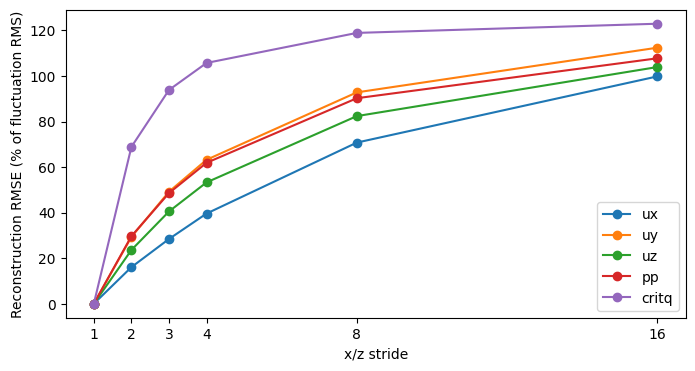

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in FIELDS:
    field_summary = summary[summary['field'] == name]
    ax.plot(field_summary['stride'], field_summary['fluctuation_error_pct'], 'o-', label=name)
ax.set(xticks=sorted(set(STRIDES)), xlabel='x/z stride', ylabel='Reconstruction RMSE (% of fluctuation RMS)')
ax.legend()
plt.show()

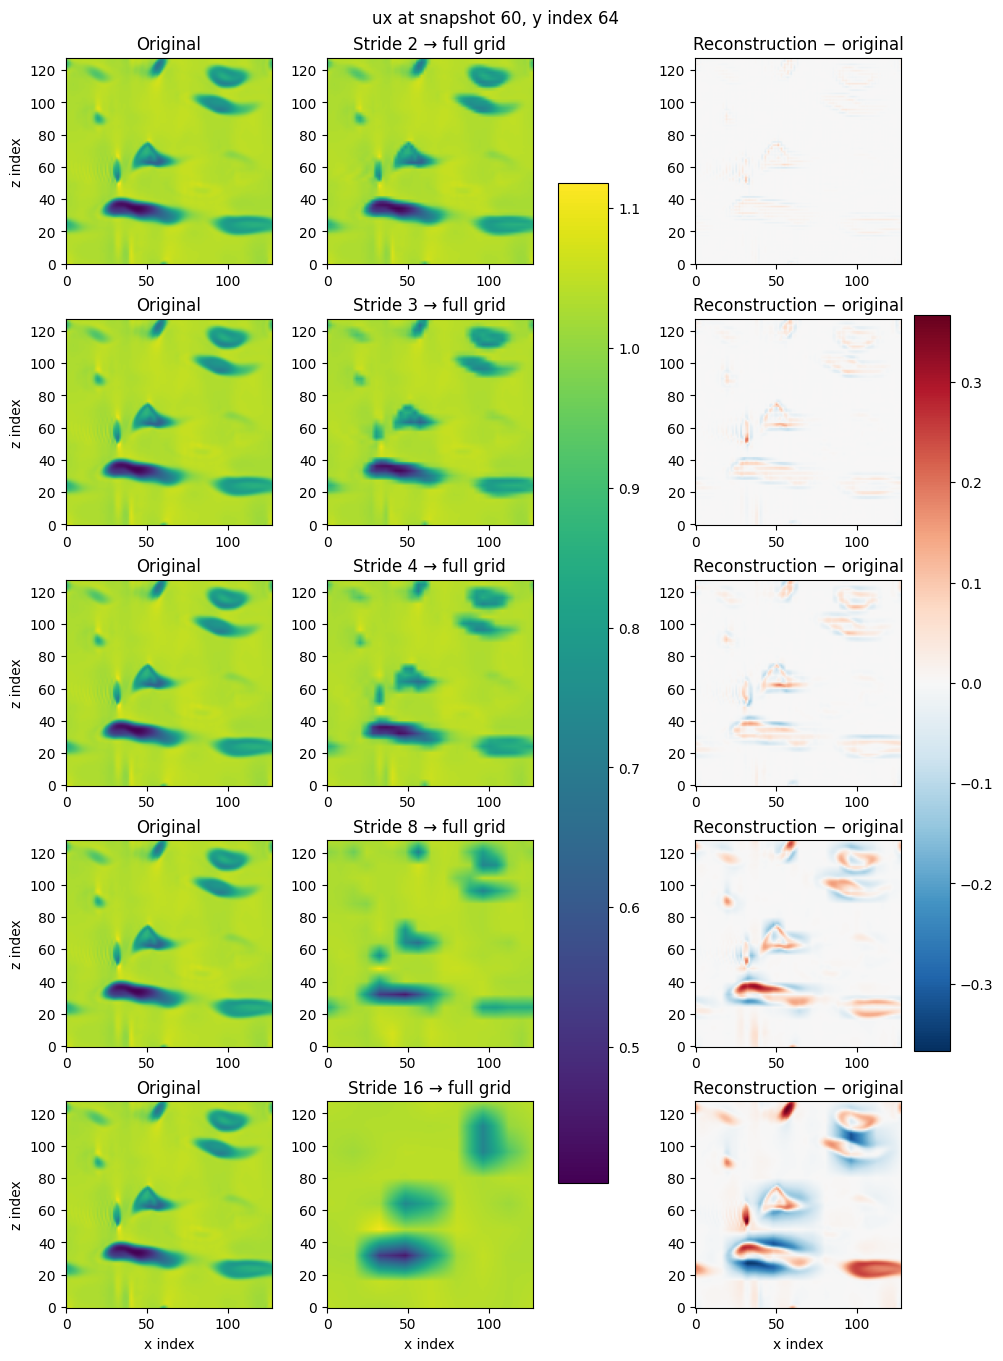

In [6]:
original = example['original']
restored = example['reconstructed']
shown = [s for s in sorted(restored) if s != 1] or [1]
fig, axes = plt.subplots(len(shown), 3, figsize=(10, 2.7 * len(shown)), squeeze=False, layout='constrained')
vmin, vmax = original.min(), original.max()
emax = max(float(np.abs(restored[s] - original).max()) for s in shown) or 1.0
for s, (ax0, ax1, ax2) in zip(shown, axes):
    ax0.imshow(original.T, origin='lower', vmin=vmin, vmax=vmax)
    field_image = ax1.imshow(restored[s].T, origin='lower', vmin=vmin, vmax=vmax)
    error_image = ax2.imshow((restored[s] - original).T, origin='lower', cmap='RdBu_r', vmin=-emax, vmax=emax)
    ax0.set(title='Original', ylabel='z index')
    ax1.set(title=f'Stride {s} → full grid')
    ax2.set(title='Reconstruction − original')
for ax in axes[-1]:
    ax.set_xlabel('x index')
fig.colorbar(field_image, ax=axes[:, :2].ravel().tolist(), shrink=0.8)
fig.colorbar(error_image, ax=axes[:, 2].tolist(), shrink=0.8)
fig.suptitle(f"{PLOT_FIELD} at snapshot {example['snapshot']}, y index {example['y']}")
plt.show()